# Environment Setup

Install extra packages not preinstalled on Kaggle/Colab: `timm` (ViT/small), `albumentations` (augmentation), `torchmetrics` (accuracy/F1/AUROC).

In [3]:
!pip install timm albumentations torchmetrics -q

# COVID / Normal / Bacterial / Viral Pneumonia — 4 Experiment Pipeline

Extends the original 3-class (Normal / Bacterial / Viral) EfficientNet-B2 pipeline to a 4-class
dataset that adds **COVID-19**, and runs **4 separate classification experiments** on it:

1. **Viral vs COVID** (binary)
2. **COVID vs Normal vs Bacterial** (3-class)
3. **Normal vs Bacterial vs Viral vs COVID** (4-class, full problem)
4. **Normal vs Pneumonia** (binary — Bacterial + Viral merged into one "Pneumonia" class)

Each experiment gets its own: train/val loss curve, train/val accuracy curve, confusion matrix,
ROC-AUC curve, and a grid of misclassified images.

> **Expected folder layout** (edit `CFG.data_dir` / folder names in the cell below if yours differs):
> ```
> data_dir/
>   train/
>     COVID/
>     Normal/
>     Pneumonia-Bacterial/
>     Pneumonia-Viral/
>   val/
>     COVID/
>     Normal/
>     Pneumonia-Bacterial/
>     Pneumonia-Viral/
> ```


In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score, MulticlassAUROC
from matplotlib.ticker import MaxNLocator

# TPU support: use torch_xla if available (Kaggle TPU runtime ships it preinstalled)
try:
    import torch_xla.core.xla_model as xm
    USE_TPU = True
except ImportError:
    USE_TPU = False

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(42)
if USE_TPU:
    device = xm.xla_device()
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| TPU:", USE_TPU)


Device: cuda | TPU: False


## Config — edit `data_dir` and the folder names inside `EXPERIMENTS` if your dataset uses different names

In [7]:
class CFG:
    data_dir   = "/kaggle/input/datasets/emonkhan222/chest-xray19"   # <-- EDIT: match your attached dataset's folder name under /kaggle/input
    train_dir  = os.path.join(data_dir, "train")
    val_dir    = os.path.join(data_dir, "val")
    test_dir   = os.path.join(data_dir, "test")

    img_size        = 256
    batch_size      = 32
    num_workers     = 0  # /kaggle/input is a fast read-only mount; raise if CPU has more cores to spare
    epochs          = 40          # epochs PER experiment (4 experiments run = 4x this many total)
    lr              = 3e-4
    weight_decay    = 1e-4
    pretrained      = True
    label_smoothing = 0.1

    # --- Vision Transformer fine-tuning ---
    model_name      = "vit_small_patch16_224"
    freeze_backbone = False   # False = fine-tune the whole network (not frozen transfer learning)
    head_dropout    = 0.3
    patch_size      = 16     # must match model_name's patch size (16 for *_patch16_*)
    backbone_lr     = 3e-5   # lower LR for pretrained ViT weights -- avoids destroying them
    head_lr         = 3e-4   # higher LR for the newly-initialized classifier head

cfg = CFG()
print(f"Model: {cfg.model_name} (ViT fine-tuning, frozen={cfg.freeze_backbone}) | Image size: {cfg.img_size} | Epochs/experiment: {cfg.epochs}")

# Each entry: folder_name -> label index. Multiple folders can map to the SAME label
# (used by exp4 to merge Bacterial + Viral into one "Pneumonia" class).
EXPERIMENTS = {
    "exp1_viral_vs_covid": {
        "title": "Viral Pneumonia vs COVID-19",
        "class_map": [("Pneumonia-Viral", 0), ("COVID-19", 1)],
        "class_names": ["Viral", "COVID"],
    },
    "exp2_covid_normal_bacterial": {
        "title": "COVID vs Normal vs Bacterial Pneumonia",
        "class_map": [("COVID-19", 0), ("Normal", 1), ("Pneumonia-Bacterial", 2)],
        "class_names": ["COVID", "Normal", "Bacterial"],
    },
    "exp3_all_4class": {
        "title": "Normal vs Bacterial vs Viral vs COVID (4-Class)",
        "class_map": [("Normal", 0), ("Pneumonia-Bacterial", 1), ("Pneumonia-Viral", 2), ("COVID-19", 3)],
        "class_names": ["Normal", "Bacterial", "Viral", "COVID"],
    },
    "exp4_normal_vs_pneumonia": {
        "title": "Normal vs Pneumonia (Bacterial + Viral merged)",
        "class_map": [("Normal", 0), ("Pneumonia-Bacterial", 1), ("Pneumonia-Viral", 1)],
        "class_names": ["Normal", "Pneumonia"],
    },
}


Model: vit_small_patch16_224 (ViT fine-tuning, frozen=False) | Image size: 256 | Epochs/experiment: 40


## Model — ViT transfer learning

ImageNet-pretrained Vision Transformer (`timm`, default `vit_small_patch16_224`, `dynamic_img_size=True` so it accepts `cfg.img_size` != 224). Backbone **frozen** by default (`cfg.freeze_backbone = True`) — only a new classifier head trains on the pooled ViT output. Set `freeze_backbone = False` for full fine-tuning.

In [8]:
class ViTClassifier(nn.Module):
    def __init__(self, num_classes, vit_name="vit_small_patch16_224", pretrained=True,
                 freeze_backbone=True, dropout=0.3):
        super().__init__()
        try:
            self.backbone = timm.create_model(vit_name, pretrained=pretrained, num_classes=0,
                                               dynamic_img_size=True)
        except TypeError:
            self.backbone = timm.create_model(vit_name, pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features

        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(feat_dim, num_classes),
        )

    def forward(self, x):
        feats = self.backbone(x)      # pooled (CLS-token) feature, (B, feat_dim)
        return self.head(feats)


## Transforms (shared across all experiments)

In [9]:
train_transforms = A.Compose([
    A.Resize(cfg.img_size + 32, cfg.img_size + 32),
    A.RandomCrop(cfg.img_size, cfg.img_size),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.06, scale_limit=0.12, rotate_limit=15, p=0.6),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(cfg.img_size, cfg.img_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_58/600052207.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
/tmp/ipykernel_58/600052207.py:8: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.3),


## Dataset — takes a flexible `class_map` so folders can be included, excluded, or merged per experiment

In [10]:
class FlexDataset(Dataset):
    """root_dir/<folder_name>/*.png|jpg -> label, per class_map=[(folder_name, label), ...].
    Multiple folders can map to the same label (merging classes, e.g. exp4)."""
    def __init__(self, root_dir, class_map, transform=None):
        self.transform = transform
        self.samples = []
        for folder_name, label in class_map:
            cls_dir = os.path.join(root_dir, folder_name)
            if not os.path.exists(cls_dir):
                raise FileNotFoundError(
                    f"Folder not found: {cls_dir}\n"
                    f"Update CFG.data_dir or the folder names in EXPERIMENTS to match your dataset."
                )
            for img_name in os.listdir(cls_dir):
                if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.samples.append((os.path.join(cls_dir, img_name), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = np.array(Image.open(img_path).convert("RGB"))
        if self.transform:
            image = self.transform(image=image)["image"]
        return image, label


## Model builder, train/validate loops (MixUp kept, generic over num_classes)

In [14]:
def build_model(num_classes):
    m = ViTClassifier(
        num_classes=num_classes,
        vit_name=cfg.model_name,
        pretrained=cfg.pretrained,
        freeze_backbone=cfg.freeze_backbone,
        dropout=cfg.head_dropout,
    )
    return m.to(device)


def train_one_epoch(model, loader, criterion, optimizer, device, acc_metric, f1_metric):
    model.train()
    running_loss = 0.0
    n_samples = 0
    acc_metric.reset()
    f1_metric.reset()

    pbar = tqdm(loader, desc="Train")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        if USE_TPU:
            xm.optimizer_step(optimizer)   # all-reduce (no-op on 1 core) + step + mark_step
        else:
            optimizer.step()

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_samples += bs

        preds = outputs.softmax(dim=1)
        acc_metric.update(preds, labels)
        f1_metric.update(preds, labels)
        pbar.set_postfix(loss=loss.item())

    return running_loss / n_samples, acc_metric.compute().item(), f1_metric.compute().item()


@torch.no_grad()
def validate(model, loader, criterion, device, acc_metric, f1_metric, auroc_metric,
             return_paths=False, dataset=None):
    model.eval()
    running_loss = 0.0
    n_samples = 0
    acc_metric.reset()
    f1_metric.reset()
    auroc_metric.reset()

    all_preds, all_labels, all_probs = [], [], []

    for images, labels in tqdm(loader, desc="Val"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_samples += bs
        preds = outputs.softmax(dim=1)

        acc_metric.update(preds, labels)
        f1_metric.update(preds, labels)
        auroc_metric.update(preds, labels)

        all_probs.extend(preds.cpu().numpy())
        all_preds.extend(preds.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    img_paths = [p for p, _ in dataset.samples] if (return_paths and dataset is not None) else None

    return (running_loss / n_samples,
            acc_metric.compute().item(),
            f1_metric.compute().item(),
            auroc_metric.compute().item(),
            all_preds, all_labels, all_probs, img_paths)


## Plotting helpers — loss/accuracy curves, confusion matrix, ROC-AUC, misclassified images

In [15]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)   # 1-indexed, integer epoch numbers

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Val")
    axes[0].set_title(f"{title} — Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))

    axes[1].plot(epochs, history["train_acc"], label="Train Acc")
    axes[1].plot(epochs, history["val_acc"], label="Val Acc")
    axes[1].plot(epochs, history["val_f1"], label="Val Macro F1")
    axes[1].set_title(f"{title} — Accuracy / F1"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout(); plt.show()


def plot_confusion(labels, preds, class_names, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(2 + 2 * len(class_names), 2 + 2 * len(class_names) * 0.75))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return cm


def plot_roc_auc(labels, probs, class_names, title):
    n_classes = len(class_names)
    labels = np.array(labels); probs = np.array(probs)
    plt.figure(figsize=(7, 6))

    if n_classes == 2:
        fpr, tpr, _ = roc_curve(labels, probs[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_names[1]} vs {class_names[0]} (AUC={roc_auc:.3f})")
    else:
        y_bin = label_binarize(labels, classes=list(range(n_classes)))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"ROC-AUC — {title}")
    plt.legend(loc="lower right")
    plt.show()


def show_misclassified(img_paths, labels, preds, class_names, title, n=12):
    mis_idx = [i for i, (l, p) in enumerate(zip(labels, preds)) if l != p]
    print(f"Misclassified: {len(mis_idx)}/{len(labels)}")
    if not mis_idx:
        print("No misclassified images."); return

    sample = mis_idx[:n]
    cols = 4
    rows = int(np.ceil(len(sample) / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, idx in enumerate(sample):
        img = Image.open(img_paths[idx]).convert("RGB")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"True: {class_names[labels[idx]]}\nPred: {class_names[preds[idx]]}",
                   fontsize=9, color="red")
        plt.axis("off")
    plt.suptitle(f"Misclassified Samples — {title}")
    plt.tight_layout(); plt.show()


## XAI — Grad-CAM (ViT-adapted)

Standard Grad-CAM assumes a spatial `(C, H, W)` conv feature map. A ViT has no such map — instead it hooks the last transformer block's patch tokens `(N, D)`, channel-weights them by the average gradient across tokens (tokens stand in for "spatial locations"), then reshapes the per-token importance score back into the patch grid (`img_size / patch_size` per side) before upsampling to the image.

In [18]:
class GradCAMViT:
    """Grad-CAM adapted for ViT: hooks the last transformer block's INPUT tokens (B, N[+prefix], D)
    -- not its output. This matters: classification pools only the CLS token, and LayerNorm/pooling
    after the last block don't mix across tokens, so the gradient into the block's OUTPUT at patch
    positions is exactly zero. Hooking the INPUT captures gradient from before the block's own
    self-attention mixes patch information into the CLS token, where patch-token gradients are
    actually non-zero. Channel-weights by the gradient averaged over tokens (Grad-CAM's spatial-average
    step, tokens standing in for spatial locations), drops CLS/prefix tokens, reshapes the remaining
    per-token score back into the patch grid."""
    def __init__(self, model, target_block):
        self.model = model
        self.activations = None
        self.gradients = None
        target_block.register_forward_pre_hook(self._forward_pre_hook)
        target_block.register_full_backward_hook(self._backward_hook)

    def _forward_pre_hook(self, module, inp):
        self.activations = inp[0]

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_in[0]

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        x = x.clone().requires_grad_(True)   # needed when backbone is frozen: grad must flow via the input
        logits = self.model(x)
        if class_idx is None:
            class_idx = logits.argmax(dim=1)
        score = logits[torch.arange(x.size(0)), class_idx].sum()
        score.backward()

        n_prefix = getattr(self.model.backbone, "num_prefix_tokens", 1)
        acts = self.activations[:, n_prefix:, :]     # (B, N, D) drop CLS/register tokens
        grads = self.gradients[:, n_prefix:, :]

        weights = grads.mean(dim=1, keepdim=True)     # (B, 1, D) channel importance
        cam = F.relu((weights * acts).sum(dim=2))      # (B, N)

        B, N = cam.shape
        side = int(N ** 0.5)
        cam = cam[:, :side * side].reshape(B, side, side)

        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.detach().cpu().numpy(), logits.detach(), class_idx.detach()


def run_xai(model, dataset, class_names, device, title, n=6, seed=0):
    """Grad-CAM, for a handful of test images."""
    model.eval()
    cam_extractor = GradCAMViT(model, model.backbone.blocks[-1])

    rng = random.Random(seed)
    idxs = rng.sample(range(len(dataset)), min(n, len(dataset)))

    cols = 3
    rows = int(np.ceil(len(idxs) / cols))
    plt.figure(figsize=(5 * cols, 5 * rows))

    for i, idx in enumerate(idxs):
        img_path, true_label = dataset.samples[idx]
        image, _ = dataset[idx]
        x = image.unsqueeze(0).to(device)

        cam, logits, pred_idx = cam_extractor(x)
        pred_label = pred_idx.item()

        cam_resized = np.array(
            Image.fromarray((cam[0] * 255).astype(np.uint8)).resize((cfg.img_size, cfg.img_size), Image.BILINEAR)
        ) / 255.0
        heatmap = plt.cm.jet(cam_resized)[..., :3]

        orig = np.array(Image.open(img_path).convert("RGB").resize((cfg.img_size, cfg.img_size))) / 255.0
        overlay = 0.55 * orig + 0.45 * heatmap

        correct = pred_label == true_label
        plt.subplot(rows, cols, i + 1)
        plt.imshow(overlay)
        plt.axis("off")
        plt.title(f"{'✓' if correct else '✗'}  True: {class_names[true_label]} | Pred: {class_names[pred_label]}",
                  fontsize=9, color=("green" if correct else "red"))

    plt.suptitle(f"Grad-CAM — {title}")
    plt.tight_layout(); plt.show()
    model.zero_grad()


## `run_experiment` — full pipeline for one experiment (train, evaluate, all plots)

In [19]:
def run_experiment(exp_key, epochs=None):
    seed_everything(42)  # FIX: reseed per experiment for independent reproducibility
    exp = EXPERIMENTS[exp_key]
    title = exp["title"]; class_map = exp["class_map"]; class_names = exp["class_names"]
    num_classes = len(class_names)
    ep = epochs or cfg.epochs

    print("=" * 70)
    print(f"EXPERIMENT [{exp_key}]: {title}")
    print("=" * 70)

    train_dataset = FlexDataset(cfg.train_dir, class_map, transform=train_transforms)
    val_dataset   = FlexDataset(cfg.val_dir,   class_map, transform=val_transforms)
    test_dataset  = FlexDataset(cfg.test_dir,  class_map, transform=val_transforms)
    print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

    train_labels = [l for _, l in train_dataset.samples]
    print("Class distribution (train):", Counter(train_labels))

    class_counts = np.bincount(train_labels, minlength=num_classes)
    class_weights = 1.0 / np.maximum(class_counts, 1)
    class_weights = class_weights / class_weights.sum() * num_classes
    class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
    print("Class weights:", class_weights)

    train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size, shuffle=True,
                               num_workers=cfg.num_workers, pin_memory=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=cfg.batch_size, shuffle=False,
                             num_workers=cfg.num_workers, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=cfg.batch_size, shuffle=False,
                              num_workers=cfg.num_workers, pin_memory=True)

    model = build_model(num_classes)
    print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M "
          f"(trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.2f}M)")

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg.label_smoothing)
    backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
    head_params = [p for p in model.head.parameters() if p.requires_grad]
    optimizer = optim.AdamW([
        {"params": backbone_params, "lr": cfg.backbone_lr},
        {"params": head_params, "lr": cfg.head_lr},
    ], weight_decay=cfg.weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)

    acc_metric   = MulticlassAccuracy(num_classes=num_classes).to(device)
    f1_metric    = MulticlassF1Score(num_classes=num_classes, average="macro").to(device)
    auroc_metric = MulticlassAUROC(num_classes=num_classes).to(device)

    best_f1 = 0.0
    ckpt_path = f"best_{exp_key}.pth"
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    for epoch in range(ep):
        print(f"\n----- [{exp_key}] Epoch {epoch + 1}/{ep} -----")
        train_loss, train_acc, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, device, acc_metric, f1_metric)
        val_loss, val_acc, val_f1, val_auroc, _, _, _, _ = validate(
            model, val_loader, criterion, device, acc_metric, f1_metric, auroc_metric)
        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        print(f"Train -> Loss:{train_loss:.4f} Acc:{train_acc:.4f} F1:{train_f1:.4f}")
        print(f"Val   -> Loss:{val_loss:.4f} Acc:{val_acc:.4f} F1:{val_f1:.4f} AUROC:{val_auroc:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            if USE_TPU:
                xm.save(model.state_dict(), ckpt_path)   # syncs XLA tensors to CPU before saving
            else:
                torch.save(model.state_dict(), ckpt_path)
            print(f"-> Saved best model (Val Macro F1: {best_f1:.4f})")

    # Final unbiased evaluation on the held-out TEST split
    model.load_state_dict(torch.load(ckpt_path, map_location="cpu" if USE_TPU else None))
    model.to(device)
    test_loss, test_acc, test_f1, test_auroc, preds, labels, probs, img_paths = validate(
        model, test_loader, criterion, device, acc_metric, f1_metric, auroc_metric,
        return_paths=True, dataset=test_dataset)

    print(f"\n========== TEST RESULTS — {title} ==========")
    print(f"Accuracy : {test_acc:.4f}")
    print(f"Macro F1 : {test_f1:.4f}")
    print(f"AUROC    : {test_auroc:.4f}")
    print("\nClassification Report (Test):")
    print(classification_report(labels, preds, target_names=class_names, digits=4))

    plot_history(history, title)
    cm = plot_confusion(labels, preds, class_names, title)
    plot_roc_auc(labels, probs, class_names, title)
    show_misclassified(img_paths, labels, preds, class_names, title)
    run_xai(model, test_dataset, class_names, device, title)

    return {"exp_key": exp_key, "title": title, "history": history,
            "test_acc": test_acc, "test_f1": test_f1, "test_auroc": test_auroc, "cm": cm}

## Experiment 1 — Viral vs COVID

EXPERIMENT [exp1_viral_vs_covid]: Viral Pneumonia vs COVID-19
Train: 2055 | Val: 440 | Test: 442
Class distribution (train): Counter({0: 1159, 1: 896})
Class weights: tensor([0.8720, 1.1280], device='cuda:0')
Parameters: 21.67M (trainable: 21.67M)

----- [exp1_viral_vs_covid] Epoch 1/20 -----


Train:   0%|          | 0/64 [00:00<?, ?it/s]

Val:   0%|          | 0/14 [00:00<?, ?it/s]

Train -> Loss:0.5117 Acc:0.8142 F1:0.8140
Val   -> Loss:0.2767 Acc:0.9835 F1:0.9838 AUROC:0.9967
-> Saved best model (Val Macro F1: 0.9838)

----- [exp1_viral_vs_covid] Epoch 2/20 -----


Train:   0%|          | 0/64 [00:00<?, ?it/s]

Val:   0%|          | 0/14 [00:00<?, ?it/s]

... (53 outputs left out)

Val:   0%|          | 0/14 [00:00<?, ?it/s]

Train -> Loss:0.2230 Acc:0.9905 F1:0.9906
Val   -> Loss:0.2367 Acc:0.9835 F1:0.9838 AUROC:0.9983


Val:   0%|          | 0/14 [00:00<?, ?it/s]


========== TEST RESULTS — Viral Pneumonia vs COVID-19 ==========
Accuracy : 0.9948
Macro F1 : 0.9954
AUROC    : 0.9960

Classification Report (Test):
              precision    recall  f1-score   support

       Viral     0.9920    1.0000    0.9960       249
       COVID     1.0000    0.9896    0.9948       193

    accuracy                         0.9955       442
   macro avg     0.9960    0.9948    0.9954       442
weighted avg     0.9955    0.9955    0.9955       442



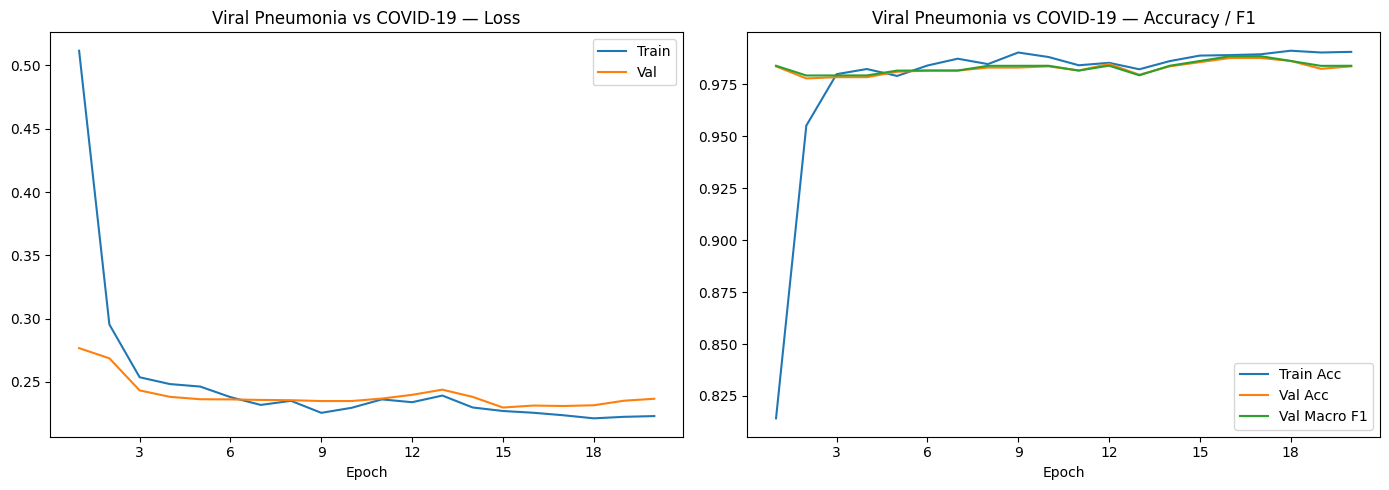

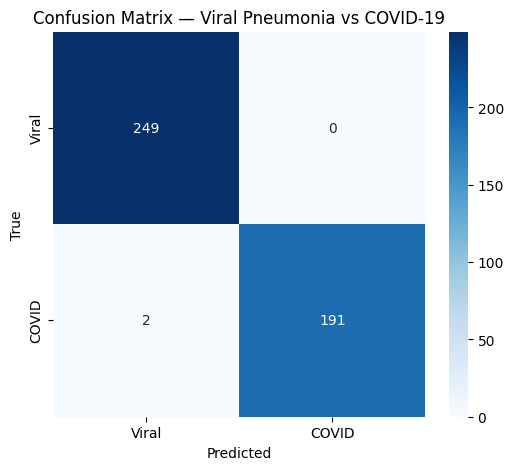

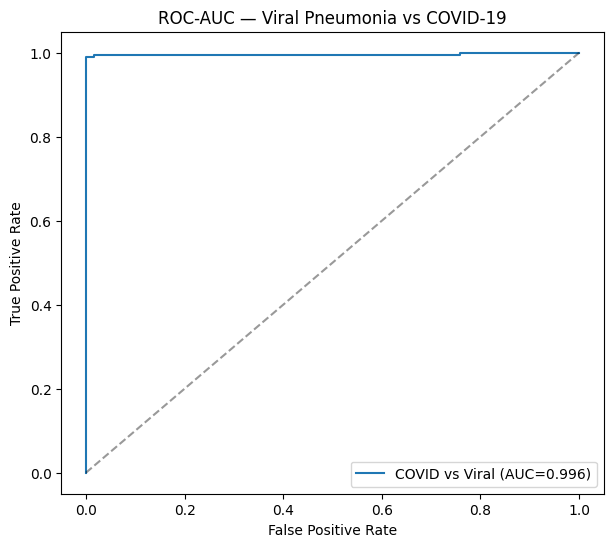

Misclassified: 2/442


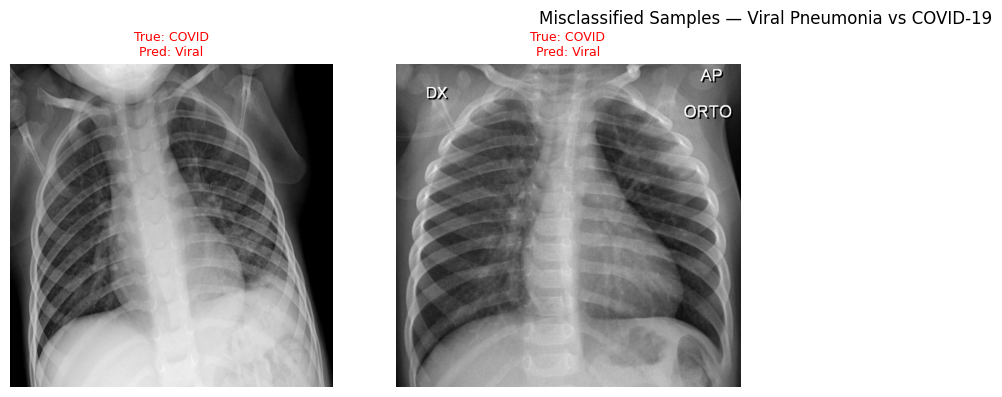

NameError: name 'F' is not defined

<Figure size 1500x1000 with 0 Axes>

In [37]:
res_exp1 = run_experiment("exp1_viral_vs_covid", epochs=20)

## Experiment 2 — COVID vs Normal vs Bacterial

EXPERIMENT [exp2_covid_normal_bacterial]: COVID vs Normal vs Bacterial Pneumonia
Train: 5285 | Val: 1132 | Test: 1135
Class distribution (train): Counter({1: 2289, 2: 2100, 0: 896})
Class weights: tensor([1.6501, 0.6459, 0.7040], device='cuda:0')
Parameters: 21.67M (trainable: 21.67M)

----- [exp2_covid_normal_bacterial] Epoch 1/20 -----


Train:   0%|          | 0/165 [00:00<?, ?it/s]

Val:   0%|          | 0/36 [00:00<?, ?it/s]

Train -> Loss:0.6667 Acc:0.8082 F1:0.7823
Val   -> Loss:0.4823 Acc:0.9541 F1:0.9554 AUROC:0.9942
-> Saved best model (Val Macro F1: 0.9554)

----- [exp2_covid_normal_bacterial] Epoch 2/20 -----


Train:   0%|          | 0/165 [00:00<?, ?it/s]

Val:   0%|          | 0/36 [00:00<?, ?it/s]

... (53 outputs left out)

Val:   0%|          | 0/36 [00:00<?, ?it/s]

Train -> Loss:0.3804 Acc:0.9790 F1:0.9775
Val   -> Loss:0.4369 Acc:0.9725 F1:0.9763 AUROC:0.9977


Val:   0%|          | 0/36 [00:00<?, ?it/s]


========== TEST RESULTS — COVID vs Normal vs Bacterial Pneumonia ==========
Accuracy : 0.9834
Macro F1 : 0.9848
AUROC    : 0.9970

Classification Report (Test):
              precision    recall  f1-score   support

       COVID     1.0000    0.9896    0.9948       193
      Normal     0.9663    0.9939    0.9799       491
   Bacterial     0.9932    0.9667    0.9798       451

    accuracy                         0.9824      1135
   macro avg     0.9865    0.9834    0.9848      1135
weighted avg     0.9827    0.9824    0.9824      1135



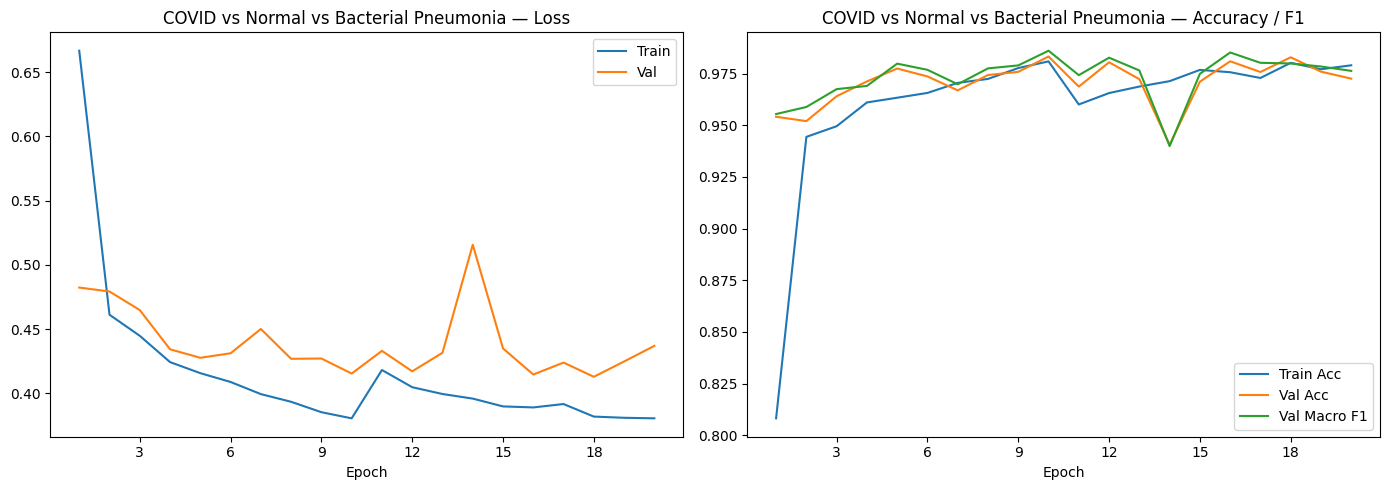

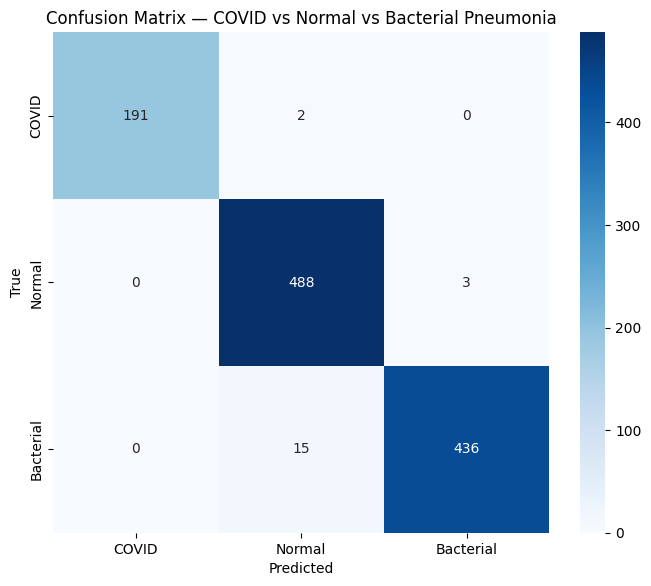

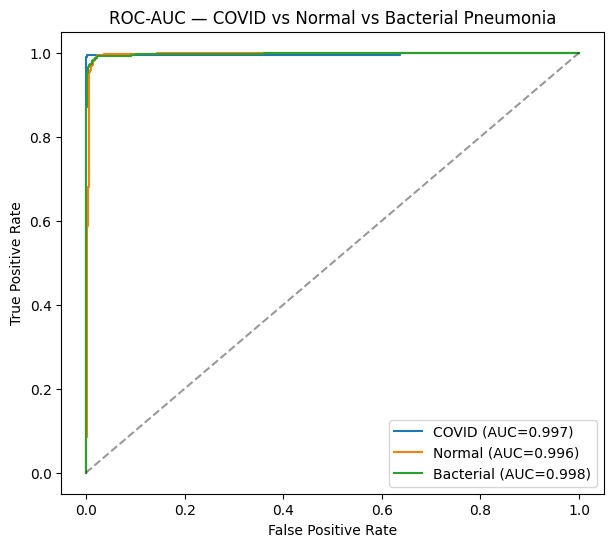

Misclassified: 20/1135


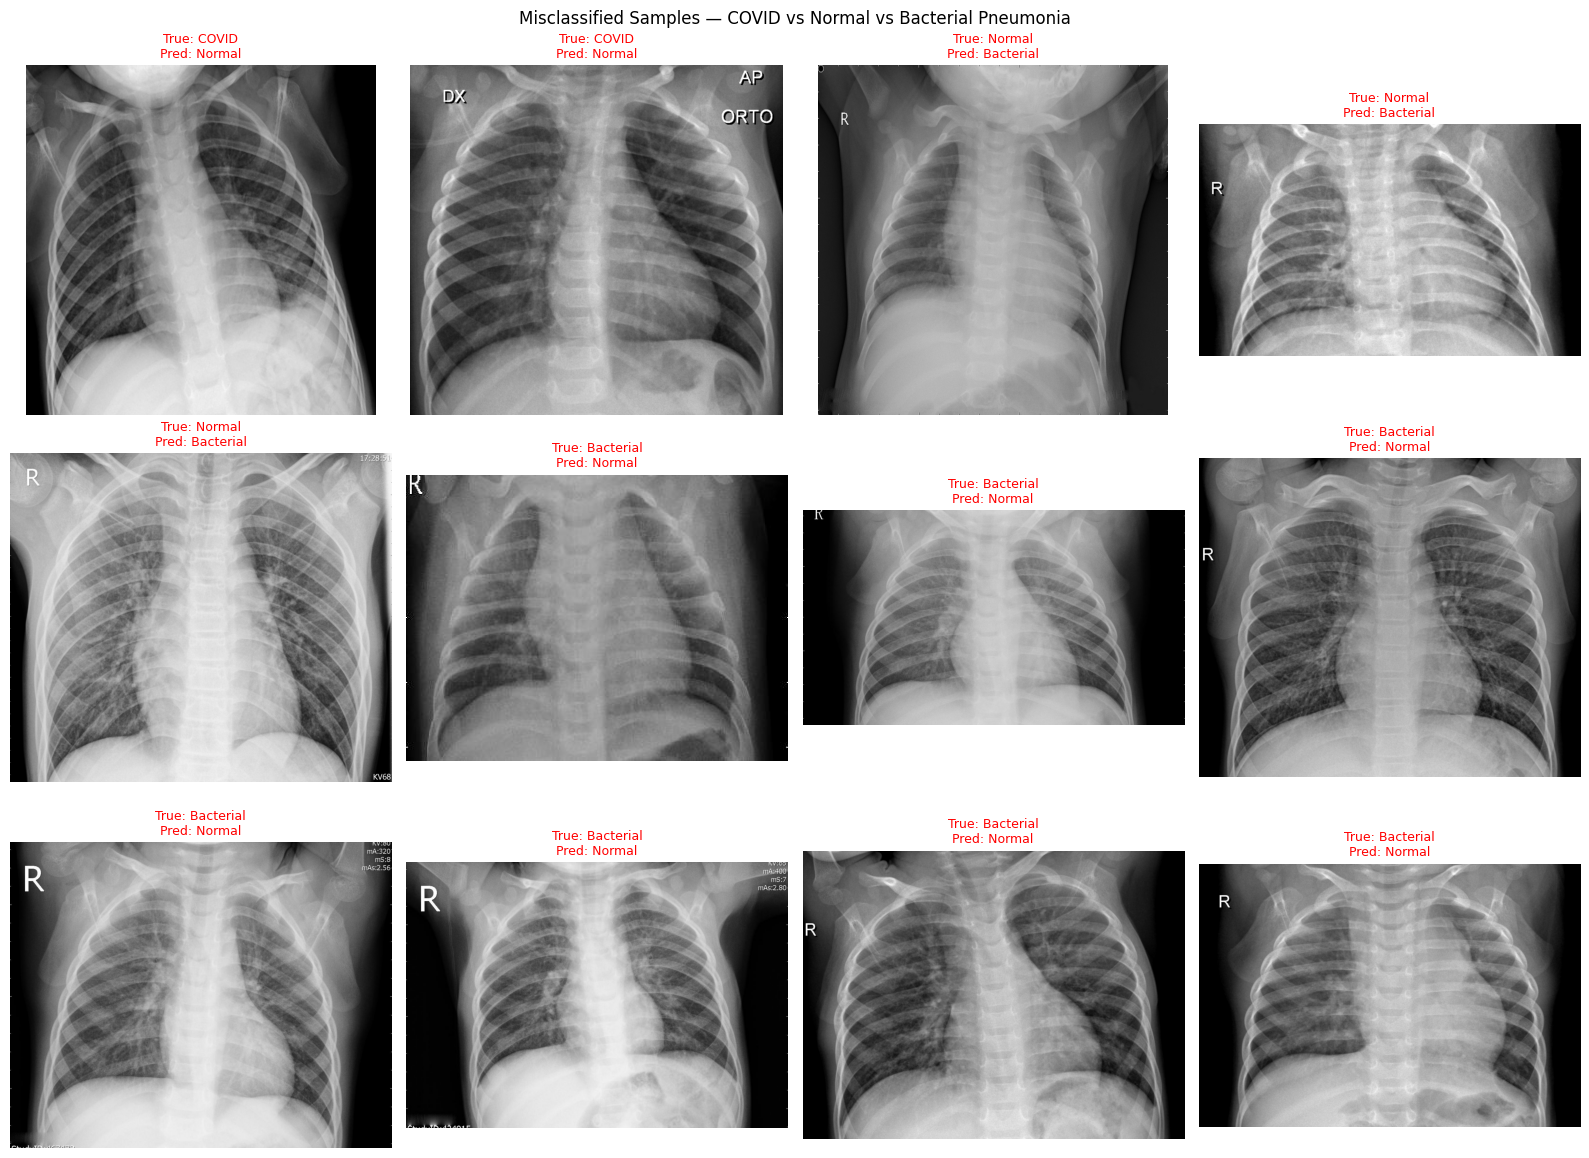

NameError: name 'F' is not defined

<Figure size 1500x1000 with 0 Axes>

In [38]:
res_exp2 = run_experiment("exp2_covid_normal_bacterial", epochs=20)

## Experiment 3 — Normal vs Bacterial vs Viral vs COVID (4-class)

EXPERIMENT [exp3_all_4class]: Normal vs Bacterial vs Viral vs COVID (4-Class)
Train: 6444 | Val: 1380 | Test: 1384
Class distribution (train): Counter({0: 2289, 1: 2100, 2: 1159, 3: 896})
Class weights: tensor([0.6043, 0.6586, 1.1934, 1.5437], device='cuda:0')


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Parameters: 21.67M (trainable: 21.67M)

----- [exp3_all_4class] Epoch 1/40 -----


Train:   0%|          | 0/201 [00:00<?, ?it/s]

Val:   0%|          | 0/44 [00:00<?, ?it/s]

Train -> Loss:1.0389 Acc:0.6183 F1:0.5917
Val   -> Loss:0.8129 Acc:0.7911 F1:0.7760 AUROC:0.9475
-> Saved best model (Val Macro F1: 0.7760)

----- [exp3_all_4class] Epoch 2/40 -----


... (114 outputs left out)

Val:   0%|          | 0/44 [00:00<?, ?it/s]

Train -> Loss:0.5499 Acc:0.9166 F1:0.9112
Val   -> Loss:0.6504 Acc:0.8761 F1:0.8791 AUROC:0.9725


Val:   0%|          | 0/44 [00:00<?, ?it/s]


========== TEST RESULTS — Normal vs Bacterial vs Viral vs COVID (4-Class) ==========
Accuracy : 0.8825
Macro F1 : 0.8828
AUROC    : 0.9696

Classification Report (Test):
              precision    recall  f1-score   support

      Normal     0.9383    0.9919    0.9644       491
   Bacterial     0.8806    0.8337    0.8565       451
       Viral     0.7265    0.7149    0.7206       249
       COVID     0.9896    0.9896    0.9896       193

    accuracy                         0.8902      1384
   macro avg     0.8838    0.8825    0.8828      1384
weighted avg     0.8886    0.8902    0.8889      1384



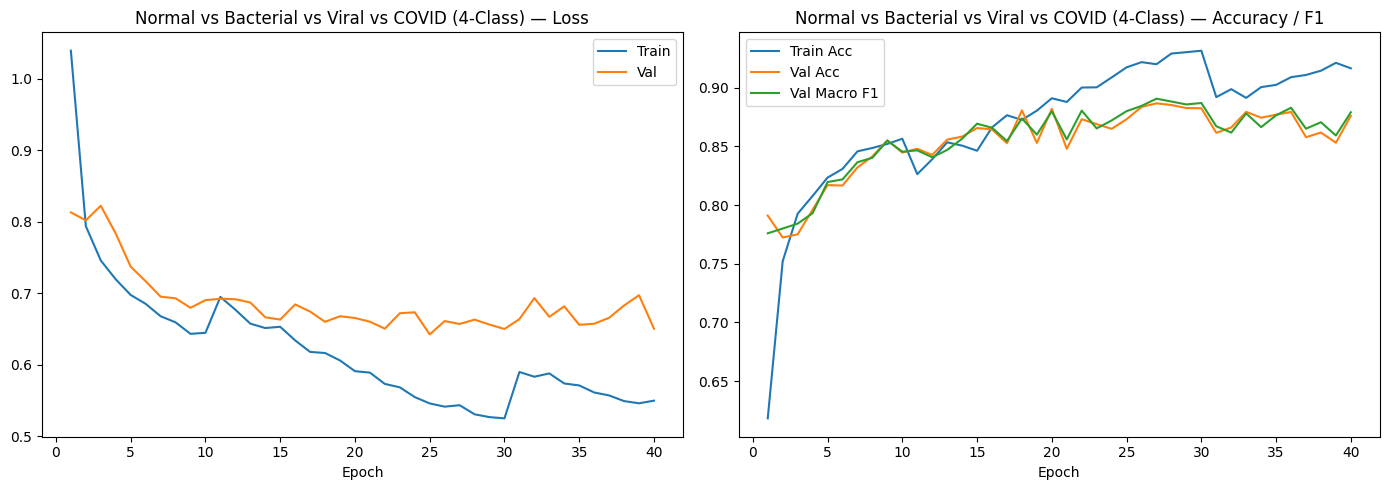

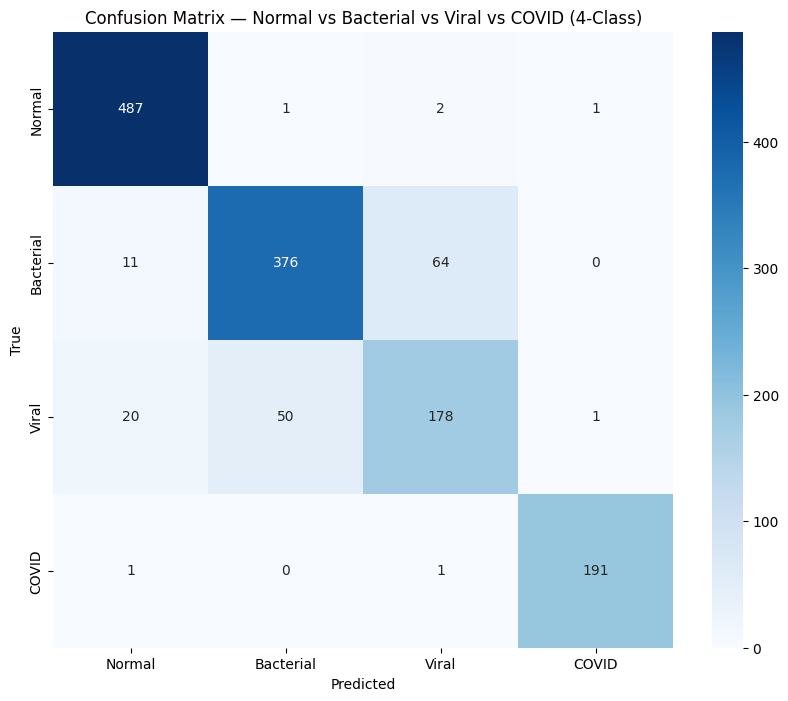

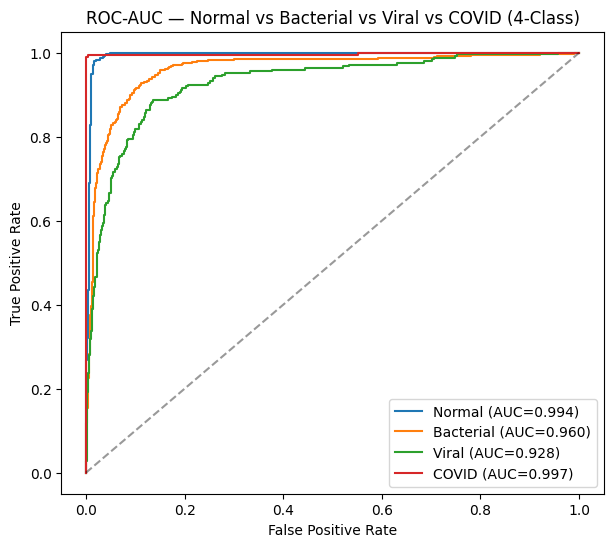

Misclassified: 152/1384


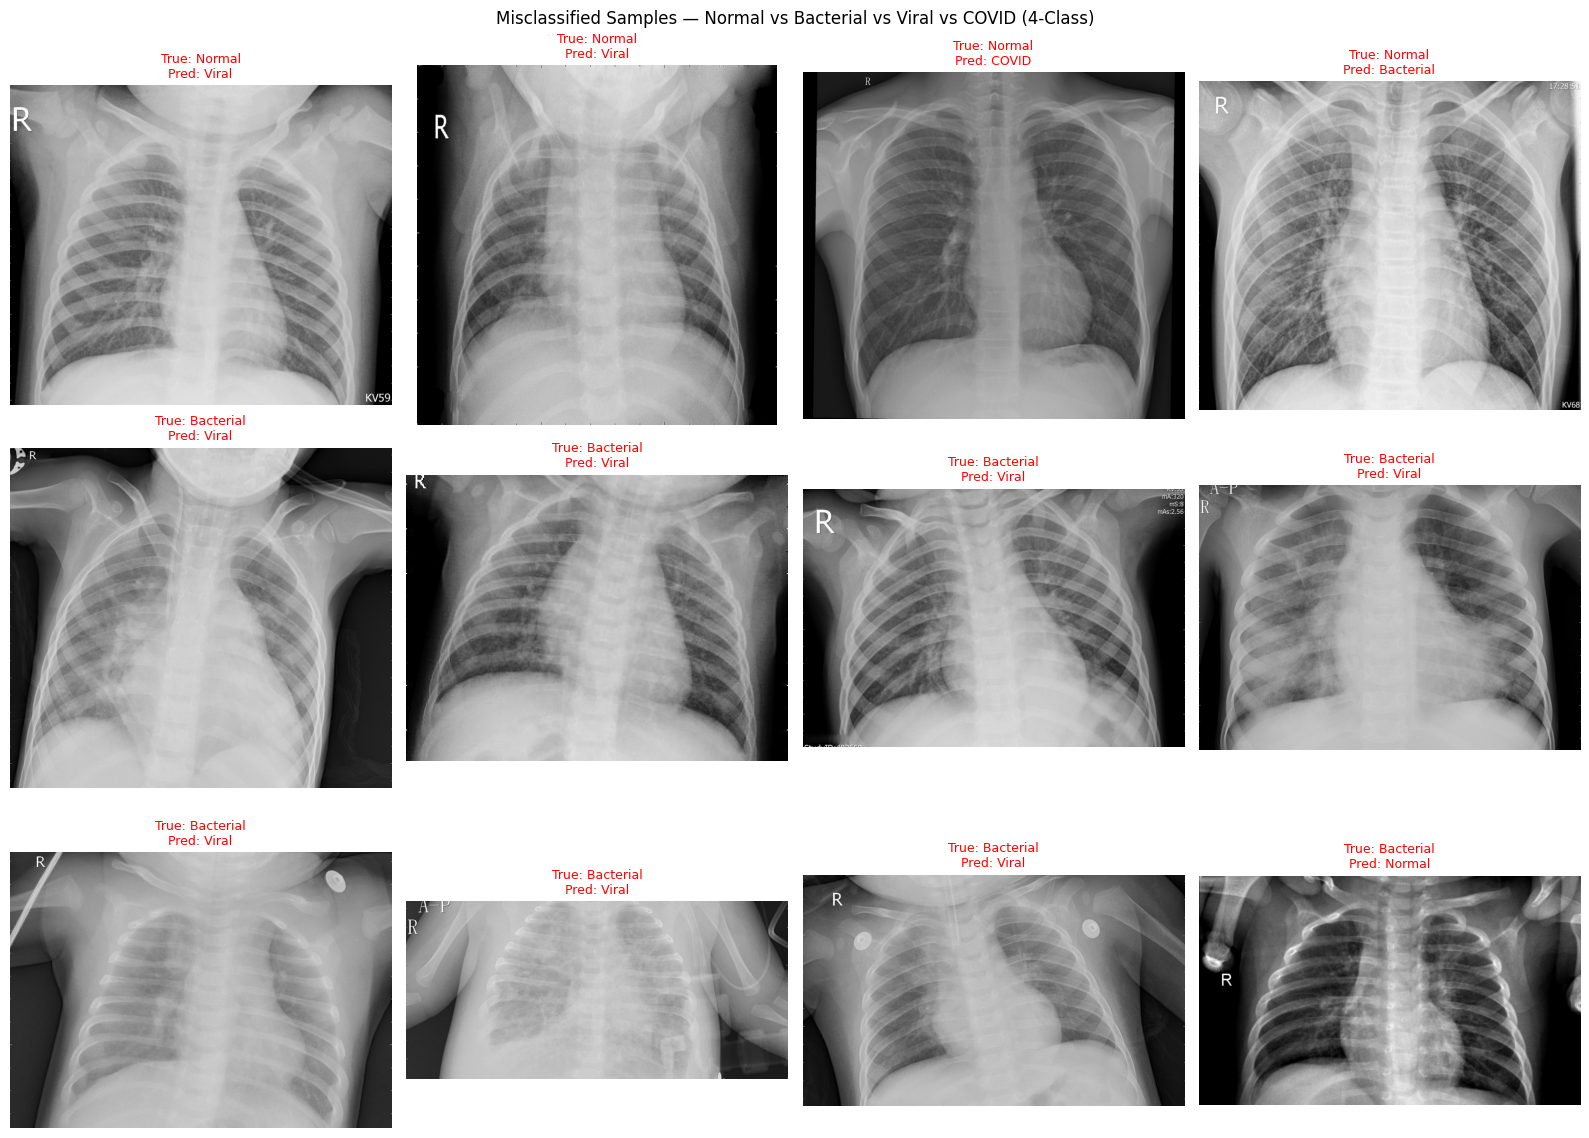

NameError: name 'F' is not defined

<Figure size 1500x1000 with 0 Axes>

In [20]:
res_exp3 = run_experiment("exp3_all_4class", epochs=40)

## Experiment 4 — Normal vs Pneumonia (Bacterial + Viral merged)

EXPERIMENT [exp4_normal_vs_pneumonia]: Normal vs Pneumonia (Bacterial + Viral merged)
Train: 5548 | Val: 1188 | Test: 1191
Class distribution (train): Counter({1: 3259, 0: 2289})
Class weights: tensor([1.1748, 0.8252], device='cuda:0')


Parameters: 21.67M (trainable: 21.67M)

----- [exp4_normal_vs_pneumonia] Epoch 1/20 -----


Train:   0%|          | 0/173 [00:00<?, ?it/s]

Val:   0%|          | 0/38 [00:00<?, ?it/s]

Train -> Loss:0.4609 Acc:0.8329 F1:0.8258
Val   -> Loss:0.2925 Acc:0.9521 F1:0.9546 AUROC:0.9918
-> Saved best model (Val Macro F1: 0.9546)

----- [exp4_normal_vs_pneumonia] Epoch 2/20 -----


Train:   0%|          | 0/173 [00:00<?, ?it/s]

... (54 outputs left out)

Val:   0%|          | 0/38 [00:00<?, ?it/s]

Train -> Loss:0.2467 Acc:0.9766 F1:0.9760
Val   -> Loss:0.2612 Acc:0.9833 F1:0.9810 AUROC:0.9967
-> Saved best model (Val Macro F1: 0.9810)


Val:   0%|          | 0/38 [00:00<?, ?it/s]


========== TEST RESULTS — Normal vs Pneumonia (Bacterial + Viral merged) ==========
Accuracy : 0.9767
Macro F1 : 0.9741
AUROC    : 0.9986

Classification Report (Test):
              precision    recall  f1-score   support

      Normal     0.9528    0.9878    0.9700       491
   Pneumonia     0.9912    0.9657    0.9783       700

    accuracy                         0.9748      1191
   macro avg     0.9720    0.9767    0.9741      1191
weighted avg     0.9754    0.9748    0.9749      1191



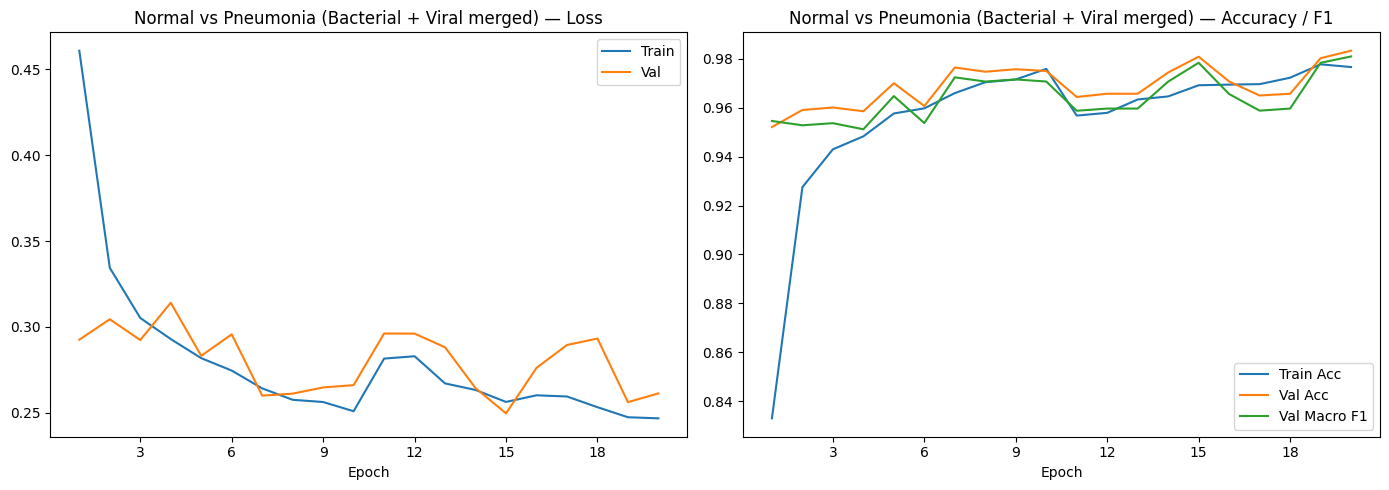

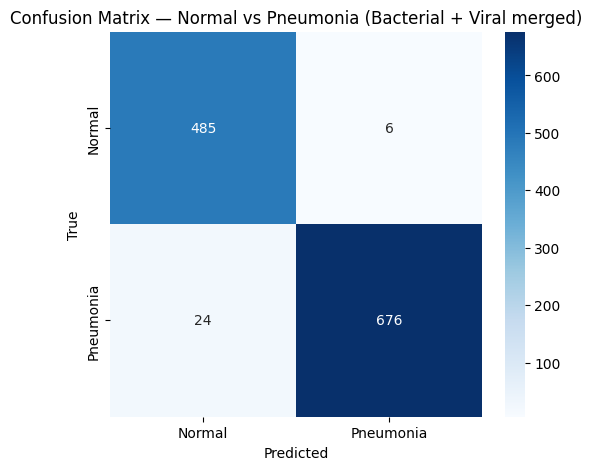

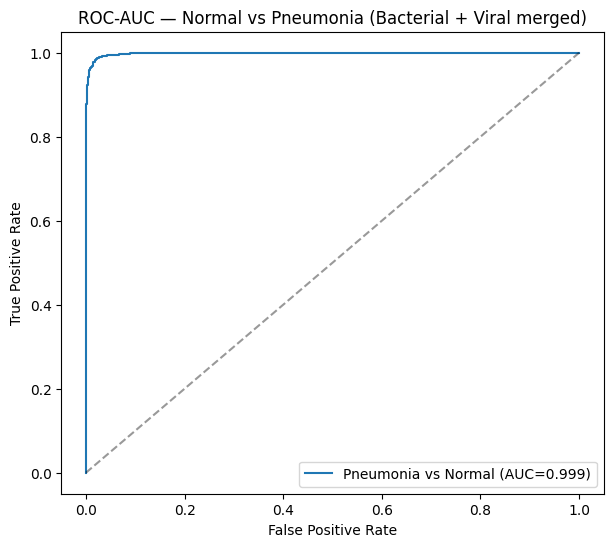

Misclassified: 30/1191


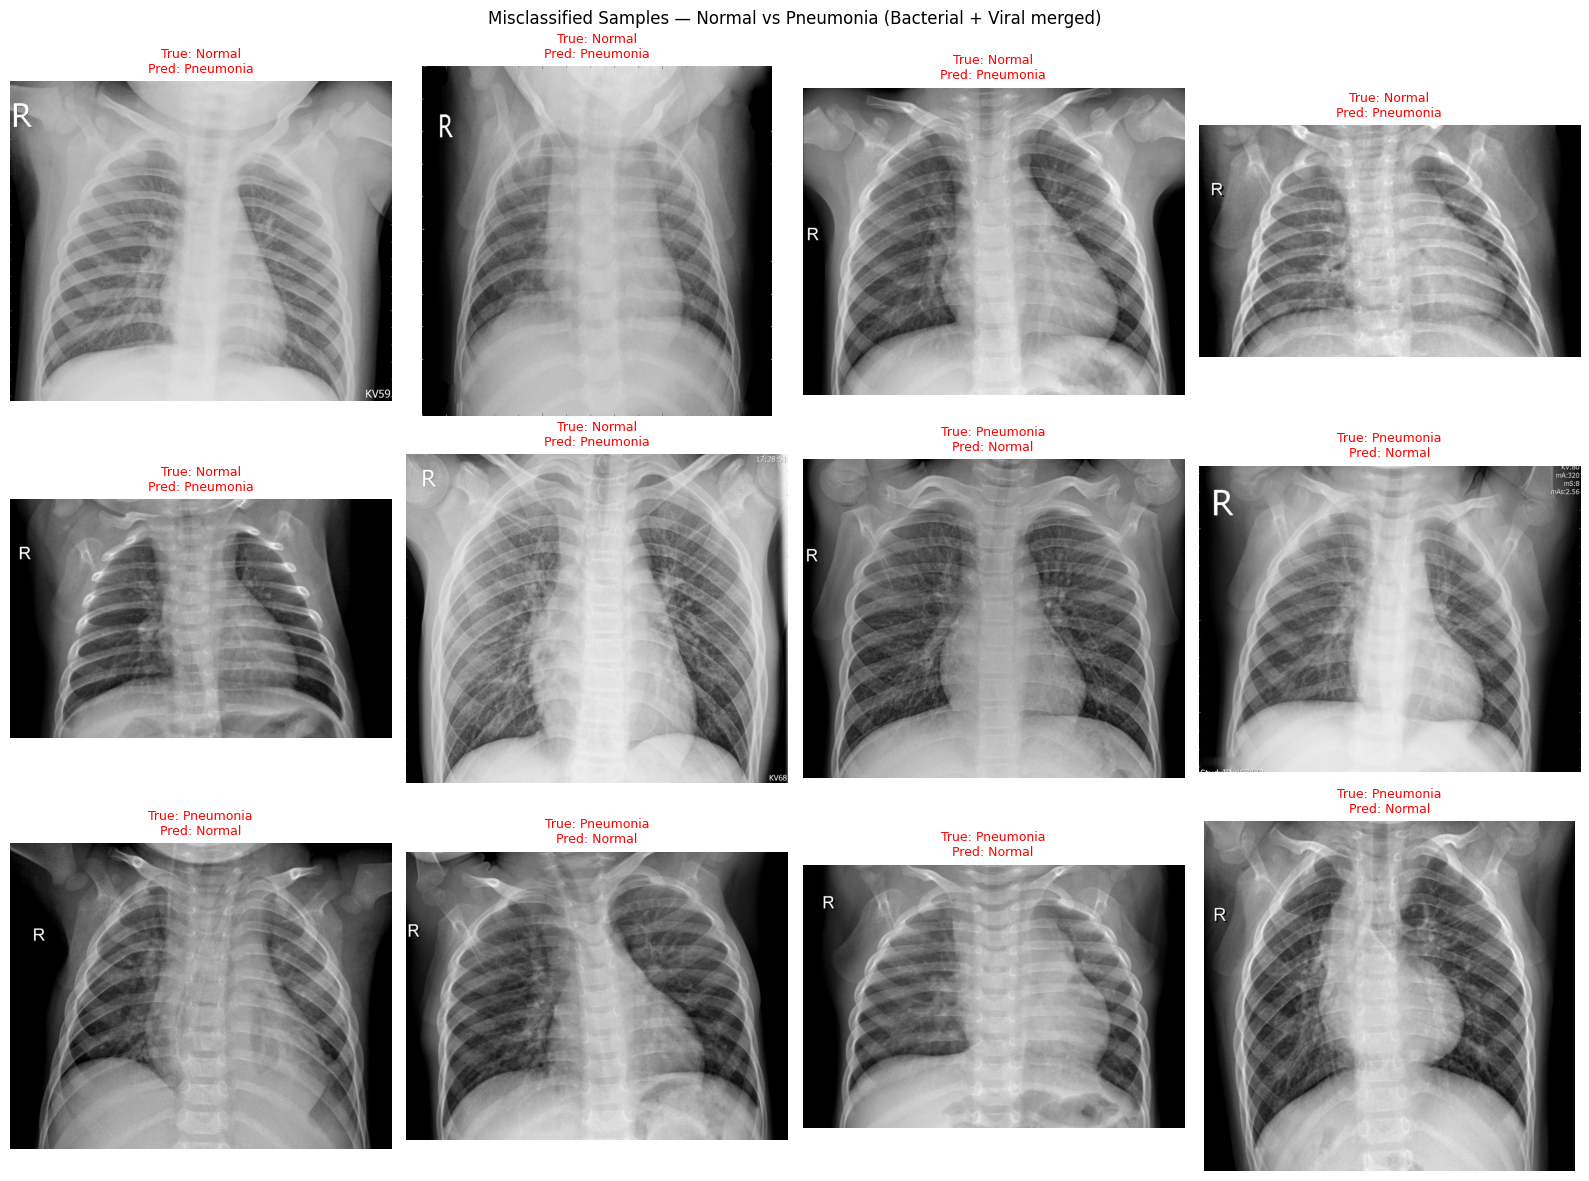

NameError: name 'F' is not defined

<Figure size 1500x1000 with 0 Axes>

In [21]:
res_exp4 = run_experiment("exp4_normal_vs_pneumonia", epochs=20)